# Cross-Domain Transfer - Source-Domain Models Applied to Sri Lanka

## What this notebook does

1. Loads the Sri Lanka held-out test split already created by `08c_Sri_Lanka_modeling.ipynb`
   (`sri_lanka_X_test_raw.csv`, `sri_lanka_y_test.csv`) — so the transfer results are evaluated
   on **exactly the same rows** as the Sri Lanka baseline (B), making the B vs. ST comparison fair.
2. For each source domain (Indonesia, Kerala, Thailand), builds a **transfer-restricted feature
   set** — only the conditioning factors that are genuinely comparable across countries — and
   trains a fresh model on the source domain using *only* those features.
3. Applies each transfer model directly to the Sri Lanka test set (no fine-tuning; pure zero-shot
   transfer) and reports the same metric suite used for the baseline.

## re-trained feature set (not the saved 08a/08b/08c models directly)

The models already saved by `08a/08b/08c` were trained on each country's **full** local factor
set, which is not identical across countries:

- Indonesia's categorical factor is `landuse` (a locally supplied raster classification) and it
  has **no SoilGrids variables** at all — it cannot be aligned with Kerala/Thailand/Sri Lanka's
  soil or landcover columns.
- `geologi` codes are assigned **independently per country** (see `07i`'s own note), so the same
  integer does not mean the same lithology across domains — it is excluded from every transfer
  variant here.
- Kerala and Thailand's `landcover` *is* the same ESA WorldCover 2021 scheme Sri Lanka uses, so
  it is safe to keep for those two sources only.


**Two transfer tiers:**

| Tier | Features | Applies to |
|---|---|---|
| `terrain_core` | elev, slope, aspect, planc, profc, twi, spi (7) | Indonesia, Kerala, Thailand |
| `terrain_soil_landcover` | terrain(7) + clay, sand, soc, bdod + landcover | Kerala, Thailand only |


## 0. Setup

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, matthews_corrcoef,
    confusion_matrix, brier_score_loss,
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PROJECT_ROOT = Path.cwd().resolve().parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROCESSED_DIR / "models"
FIGURE_DIR = PROCESSED_DIR / "figures" / "cross_domain_transfer"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Processed dir:", PROCESSED_DIR)

try:
    import xgboost as xgb
    XGBOOST_AVAILABLE = True
    print("XGBoost:", xgb.__version__)
except ImportError:
    XGBOOST_AVAILABLE = False
    print("XGBoost not installed -- only Random Forest transfer models will run.")


Processed dir: D:\PROJECTS\Landslide_prediction\data\processed
XGBoost: 3.0.0


## 1. Load the Sri Lanka target-domain test set

Reusing the split already produced by `08c_Sri_Lanka_modeling.ipynb` keeps the transfer
evaluation on the identical rows used for the Sri Lanka baseline (B), so the comparison in
Chapter 5 is apples-to-apples rather than a different random split.

In [2]:
sl_X_test_raw = pd.read_csv(PROCESSED_DIR / "sri_lanka_X_test_raw.csv")
sl_y_test = pd.read_csv(PROCESSED_DIR / "sri_lanka_y_test.csv").squeeze("columns")

print("Sri Lanka target-domain test set:", sl_X_test_raw.shape)
print("Columns available:", sl_X_test_raw.columns.tolist())
print("Class balance:\n", sl_y_test.value_counts())


Sri Lanka target-domain test set: (293, 20)
Columns available: ['elev', 'slope', 'aspect', 'planc', 'profc', 'twi', 'spi', 'clay', 'sand', 'soc', 'bdod', 'dist_to_river', 'dist_to_road', 'rain_1d', 'rain_3d', 'rain_7d', 'rain_15d', 'rain_30d', 'landcover', 'geologi']
Class balance:
 label
0    147
1    146
Name: count, dtype: int64


## 2. Evaluation helper (same metric suite as the baseline notebooks)

In [3]:
def evaluate_binary_classifier(model, X, y):
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    sensitivity = tp / (tp + fn) if (tp + fn) else np.nan
    return {
        "accuracy": accuracy_score(y, y_pred),
        "precision": precision_score(y, y_pred, zero_division=0),
        "recall": recall_score(y, y_pred, zero_division=0),
        "specificity": specificity,
        "f1": f1_score(y, y_pred, zero_division=0),
        "mcc": matthews_corrcoef(y, y_pred),
        "tss": sensitivity + specificity - 1,
        "roc_auc": roc_auc_score(y, y_proba),
        "pr_auc": average_precision_score(y, y_proba),
        "brier": brier_score_loss(y, y_proba),
        "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    }


## 3. Define the transfer feature tiers

`TERRAIN_CORE` is the only tier valid for Indonesia (no soil data, and its `landuse` layer is not
the same scheme as Sri Lanka's `landcover`). `TERRAIN_SOIL_LANDCOVER` is used for Kerala and
Thailand, which share SoilGrids and ESA WorldCover with Sri Lanka.

In [4]:
TERRAIN_CORE = ["elev", "slope", "aspect", "planc", "profc", "twi", "spi"]
SOIL = ["clay", "sand", "soc", "bdod"]
LANDCOVER = ["landcover"]

SOURCE_CONFIG = {
    "Indonesia": {
        "csv": PROCESSED_DIR / "training_table_indonesia_extended.csv",
        "tiers": {
            "terrain_core": {"continuous": TERRAIN_CORE, "categorical": []},
        },
    },
    "Kerala": {
        "csv": PROCESSED_DIR / "training_table_kerala_extended.csv",
        "tiers": {
            "terrain_core": {"continuous": TERRAIN_CORE, "categorical": []},
            "terrain_soil_landcover": {"continuous": TERRAIN_CORE + SOIL, "categorical": LANDCOVER},
        },
    },
    "Thailand": {
        "csv": PROCESSED_DIR / "training_table_thailand_extended.csv",
        "tiers": {
            "terrain_core": {"continuous": TERRAIN_CORE, "categorical": []},
            "terrain_soil_landcover": {"continuous": TERRAIN_CORE + SOIL, "categorical": LANDCOVER},
        },
    },
}

for name, cfg in SOURCE_CONFIG.items():
    print(name, "->", cfg["csv"].name, "| exists:", cfg["csv"].exists())


Indonesia -> training_table_indonesia_extended.csv | exists: True
Kerala -> training_table_kerala_extended.csv | exists: True
Thailand -> training_table_thailand_extended.csv | exists: True


## 4. Train each transfer model and score it on the Sri Lanka test set

Random Forest is used consistently across every source/tier so that differences in the results
reflect the **domain being transferred from**, not a different algorithm being compared. Swap in
your own tuned hyperparameters (e.g. from `rf_search.best_params_` in the corresponding `08*`
notebook) if you want the transfer models tuned per source as well.

In [ ]:
def build_preprocessor(continuous_cols, categorical_cols):
    transformers = []
    if continuous_cols:
        transformers.append(("continuous", StandardScaler(), continuous_cols))
    if categorical_cols:
        transformers.append(("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols))
    return ColumnTransformer(transformers)


#Because the source datasets were already approximately balanced, weighting was disabled for the final transfer experiments.
USE_BALANCED_WEIGHTING = False

def make_estimator(algorithm_name, scale_pos_weight=1.0):
    if algorithm_name == "Random Forest":
        return RandomForestClassifier(
            n_estimators=300,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            class_weight="balanced" if USE_BALANCED_WEIGHTING else None,
        )
    if algorithm_name == "XGBoost":
        return xgb.XGBClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            scale_pos_weight=scale_pos_weight if USE_BALANCED_WEIGHTING else 1.0,
        )
    raise ValueError(f"Unknown algorithm: {algorithm_name}")


def train_transfer_model(source_df, continuous_cols, categorical_cols, algorithm_name):
    feature_cols = continuous_cols + categorical_cols
    df = source_df.dropna(subset=feature_cols + ["label"]).reset_index(drop=True)

    X = df[feature_cols]
    y = df["label"].astype(int)

    n_pos = int((y == 1).sum())
    n_neg = int((y == 0).sum())
    scale_pos_weight = (n_neg / n_pos) if n_pos else 1.0

    preprocessor = build_preprocessor(continuous_cols, categorical_cols)
    model = make_estimator(algorithm_name, scale_pos_weight=scale_pos_weight)
    pipeline = Pipeline([("preprocess", preprocessor), ("model", model)])
    pipeline.fit(X, y)

    return pipeline, len(df)


ALGORITHMS = ["Random Forest", "XGBoost"] if XGBOOST_AVAILABLE else ["Random Forest"]

transfer_results = []
fitted_pipelines = {}

for source_name, cfg in SOURCE_CONFIG.items():
    if not cfg["csv"].exists():
        print(f"Skipping {source_name}: {cfg['csv']} not found.")
        continue

    source_df = pd.read_csv(cfg["csv"])

    for tier_name, cols in cfg["tiers"].items():
        continuous_cols = cols["continuous"]
        categorical_cols = cols["categorical"]
        feature_cols = continuous_cols + categorical_cols

        missing_in_sl = [c for c in feature_cols if c not in sl_X_test_raw.columns]
        if missing_in_sl:
            print(f"Skipping {source_name}/{tier_name}: Sri Lanka is missing {missing_in_sl}")
            continue

        sl_eval_df = sl_X_test_raw[feature_cols].copy()
        valid_mask = sl_eval_df.notna().all(axis=1)

        for algorithm_name in ALGORITHMS:
            # Train only on source domain
            pipeline, n_source_rows = train_transfer_model(
                source_df, continuous_cols, categorical_cols, algorithm_name
            )
            key = f"{source_name} ({tier_name}, {algorithm_name})"
            fitted_pipelines[key] = pipeline

            
            model_fname = f"transfer_{source_name}_{tier_name}_{algorithm_name}".replace(" ", "_") + ".joblib"
            joblib.dump(pipeline, MODEL_DIR / model_fname)

            result = evaluate_binary_classifier(
                pipeline,
                sl_eval_df.loc[valid_mask],
                sl_y_test.loc[valid_mask],
            )
            result["scenario"] = f"ST-{source_name}"
            result["feature_tier"] = tier_name
            result["algorithm"] = algorithm_name
            result["n_features"] = len(feature_cols)
            result["n_source_train_rows"] = n_source_rows
            result["n_target_eval_rows"] = int(valid_mask.sum())
            transfer_results.append(result)

            print(f"Done: {key}  |  F1={result['f1']:.4f}  ROC-AUC={result['roc_auc']:.4f}")

transfer_results_df = pd.DataFrame(transfer_results)
display_cols = ["scenario", "feature_tier", "algorithm", "n_features", "n_target_eval_rows",
                 "accuracy", "precision", "recall", "f1", "roc_auc", "mcc", "tss"]
transfer_results_df[display_cols].round(4)

Done: Indonesia (terrain_core, Random Forest)  |  F1=0.5704  ROC-AUC=0.6228
Done: Indonesia (terrain_core, XGBoost)  |  F1=0.5294  ROC-AUC=0.5874
Done: Kerala (terrain_core, Random Forest)  |  F1=0.5644  ROC-AUC=0.5416
Done: Kerala (terrain_core, XGBoost)  |  F1=0.6339  ROC-AUC=0.6038
Done: Kerala (terrain_soil_landcover, Random Forest)  |  F1=0.4825  ROC-AUC=0.5798
Done: Kerala (terrain_soil_landcover, XGBoost)  |  F1=0.5309  ROC-AUC=0.5792
Done: Thailand (terrain_core, Random Forest)  |  F1=0.5983  ROC-AUC=0.5160
Done: Thailand (terrain_core, XGBoost)  |  F1=0.6549  ROC-AUC=0.5617
Done: Thailand (terrain_soil_landcover, Random Forest)  |  F1=0.6667  ROC-AUC=0.6144
Done: Thailand (terrain_soil_landcover, XGBoost)  |  F1=0.6701  ROC-AUC=0.6030


,scenario,feature_tier,algorithm,n_features,n_target_eval_rows,accuracy,precision,recall,f1,roc_auc,mcc,tss
0,ST-Indonesia,terrain_core,Random Forest,7,293,0.5939,0.6031,0.5411,0.5704,0.6228,0.1884,0.1874
1,ST-Indonesia,terrain_core,XGBoost,7,293,0.5631,0.5714,0.4932,0.5294,0.5874,0.1271,0.1258
2,ST-Kerala,terrain_core,Random Forest,7,293,0.5154,0.5111,0.6301,0.5644,0.5416,0.0324,0.0315
3,ST-Kerala,terrain_core,XGBoost,7,293,0.5427,0.5273,0.7945,0.6339,0.6038,0.1006,0.0870
4,ST-Kerala,terrain_soil_landcover,Random Forest,12,293,0.5461,0.5586,0.4247,0.4825,0.5798,0.0941,0.0913
5,ST-Kerala,terrain_soil_landcover,XGBoost,12,293,0.5597,0.5659,0.5000,0.5309,0.5792,0.1199,0.1190
6,ST-Thailand,terrain_core,Random Forest,7,293,0.5188,0.5122,0.7192,0.5983,0.5160,0.0424,0.0389
7,ST-Thailand,terrain_core,XGBoost,7,293,0.5324,0.5179,0.8904,0.6549,0.5617,0.0960,0.0673
8,ST-Thailand,terrain_soil_landcover,Random Forest,12,293,0.5529,0.5304,0.8973,0.6667,0.6144,0.1486,0.1081
9,ST-Thailand,terrain_soil_landcover,XGBoost,12,293,0.5563,0.5323,0.9041,0.6701,0.6030,0.1595,0.1150


In [6]:
best_per_source_tier = (
    transfer_results_df
    .sort_values("roc_auc", ascending=False)
    .drop_duplicates(subset=["scenario", "feature_tier"])
    .sort_values(["scenario", "feature_tier"])
)

best_per_source_tier[display_cols].round(4)

,scenario,feature_tier,algorithm,n_features,n_target_eval_rows,accuracy,precision,recall,f1,roc_auc,mcc,tss
0,ST-Indonesia,terrain_core,Random Forest,7,293,0.5939,0.6031,0.5411,0.5704,0.6228,0.1884,0.1874
3,ST-Kerala,terrain_core,XGBoost,7,293,0.5427,0.5273,0.7945,0.6339,0.6038,0.1006,0.0870
4,ST-Kerala,terrain_soil_landcover,Random Forest,12,293,0.5461,0.5586,0.4247,0.4825,0.5798,0.0941,0.0913
7,ST-Thailand,terrain_core,XGBoost,7,293,0.5324,0.5179,0.8904,0.6549,0.5617,0.0960,0.0673
8,ST-Thailand,terrain_soil_landcover,Random Forest,12,293,0.5529,0.5304,0.8973,0.6667,0.6144,0.1486,0.1081


## 5. Add the Sri Lanka baseline (B) for comparison

Loads the already-saved baseline results from `08c_Sri_Lanka_modeling.ipynb` so B and every ST
scenario sit in one table.

In [7]:
baseline_path = MODEL_DIR / "sri_lanka_model_results.json"

if baseline_path.exists():
    baseline_json = json.loads(baseline_path.read_text(encoding="utf-8"))
    # Adjust the key below if your saved results JSON nests the held-out metrics differently.
    baseline_metrics = baseline_json.get("test_results") or baseline_json.get("held_out_test") or baseline_json
    baseline_row = {
        "scenario": "B (Sri Lanka baseline)",
        "feature_tier": "full_sri_lanka_feature_set",
        "n_features": np.nan,
        "n_target_eval_rows": len(sl_y_test),
    }
    for m in ["accuracy", "precision", "recall", "f1", "roc_auc", "mcc", "tss"]:
        if m in baseline_metrics:
            baseline_row[m] = baseline_metrics[m]
    comparison_df = pd.concat(
    [pd.DataFrame([baseline_row]), best_per_source_tier[display_cols]],
    ignore_index=True,
    )
else:
    print("Baseline results JSON not found -- paste your 08c held-out numbers into baseline_row manually.")
    comparison_df = transfer_results_df[display_cols]

comparison_df.round(4)


,scenario,feature_tier,n_features,n_target_eval_rows,algorithm,accuracy,precision,recall,f1,roc_auc,mcc,tss
0,B (Sri Lanka baseline),full_sri_lanka_feature_set,NaN,293,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ST-Indonesia,terrain_core,7.0,293,Random Forest,0.5939,0.6031,0.5411,0.5704,0.6228,0.1884,0.1874
2,ST-Kerala,terrain_core,7.0,293,XGBoost,0.5427,0.5273,0.7945,0.6339,0.6038,0.1006,0.0870
3,ST-Kerala,terrain_soil_landcover,12.0,293,Random Forest,0.5461,0.5586,0.4247,0.4825,0.5798,0.0941,0.0913
4,ST-Thailand,terrain_core,7.0,293,XGBoost,0.5324,0.5179,0.8904,0.6549,0.5617,0.0960,0.0673
5,ST-Thailand,terrain_soil_landcover,12.0,293,Random Forest,0.5529,0.5304,0.8973,0.6667,0.6144,0.1486,0.1081


## 6. Comparison chart - F1 and ROC-AUC, B vs. every ST scenario

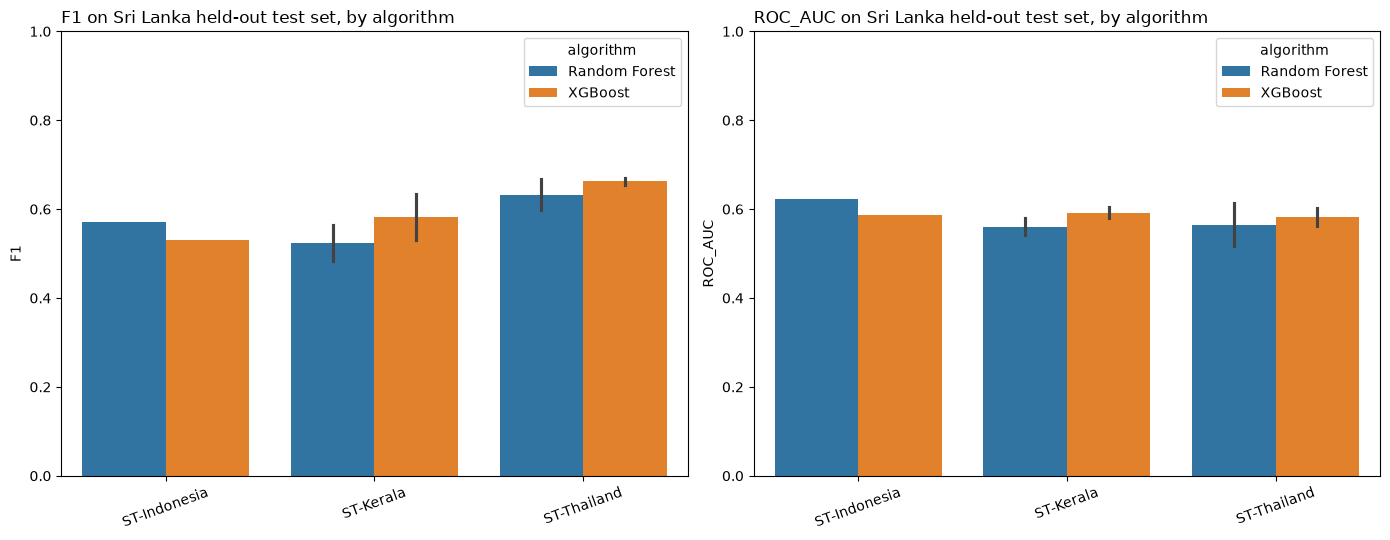

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, metric in zip(axes, ["f1", "roc_auc"]):
    sns.barplot(
        data=transfer_results_df,
        x="scenario", y=metric, hue="algorithm",
        ax=ax, dodge=True,
    )
    ax.set_title(metric.upper() + " on Sri Lanka held-out test set, by algorithm", loc="left")
    ax.set_xlabel("")
    ax.set_ylabel(metric.upper())
    ax.tick_params(axis="x", rotation=20)
    ax.set_ylim(0, 1)

plt.tight_layout()
fig.savefig(FIGURE_DIR / "transfer_algorithm_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


## 7. Save results for Chapter 5

In [9]:
results_out = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "comparison_table": comparison_df.to_dict(orient="records"),
    "full_transfer_results": transfer_results_df.to_dict(orient="records"),
}

out_path = MODEL_DIR / "cross_domain_transfer_results.json"
out_path.write_text(json.dumps(results_out, indent=2, default=str), encoding="utf-8")

comparison_df.to_csv(MODEL_DIR / "cross_domain_transfer_comparison.csv", index=False)

print("Saved:", out_path)
print("Saved:", MODEL_DIR / "cross_domain_transfer_comparison.csv")


Saved: D:\PROJECTS\Landslide_prediction\data\processed\models\cross_domain_transfer_results.json
Saved: D:\PROJECTS\Landslide_prediction\data\processed\models\cross_domain_transfer_comparison.csv


## 8. Full spatial susceptibility map (six-district AOI)

Based on `02_terrain.ipynb` and `07i_Add_Kerala_Factors_Sri_Lanka.ipynb`, here's what changed
from the original plan for this section:

- **Extent**: the only DEM in this project (`data/processed/dem_utm.tif`, SRTM 30 m) was clipped
  to the six-district AOI used for point sampling, not all of Sri Lanka. This section maps that
  AOI, not the whole country.
- **No curvature**: `02_terrain.ipynb` derives slope, aspect, TWI and SPI with WhiteboxTools, but
  never calls `plan_curvature`/`profile_curvature`, so no `planc`/`profc` raster exists. Per your
  choice, this section trains and maps a **curvature-free** variant of each transfer tier
  (`elev, slope, aspect, twi, spi` instead of the original 7-feature `TERRAIN_CORE`), evaluated
  separately below so you can see what curvature was contributing before it's dropped from the map.
- **No geology raster needed**: `geologi` is already excluded from every transfer tier (per
  Section 3's own note that geology codes aren't comparable across countries), so nothing to
  build there.
- **Soil and landcover need re-gridding**: the SoilGrids rasters and WorldCover mosaic that
  `07i` downloaded are in EPSG:4326, at a different resolution, over a different (though
  overlapping) bounding box than the DEM-derived terrain rasters, which are in UTM 44N. They're
  reprojected/resampled onto the terrain rasters' exact grid below before anything is stacked.
- **Unit conversion carried over from `07i`**: the raw SoilGrids rasters are in native SoilGrids
  units (clay/sand/soc ×10, bdod ×100 of their real values) -- the same divisors `07i` applied
  when building the point-sampled training table are applied here during re-gridding, or every
  pixel's soil values would be 10-100x too large relative to what the model was trained on.

In [10]:
try:
    import rasterio
    from rasterio.warp import reproject, Resampling
    RASTERIO_AVAILABLE = True
    print("rasterio:", rasterio.__version__)
except ImportError:
    RASTERIO_AVAILABLE = False
    print("rasterio not installed -- run `pip install rasterio` to use this section.")

rasterio: 1.4.4


### 8a. Train curvature-free transfer models and evaluate the trade-off

In [11]:
MAP_TERRAIN = ["elev", "slope", "aspect", "twi", "spi"]  # TERRAIN_CORE minus planc/profc

MAP_SOURCE_CONFIG = {
    "Indonesia": {
        "csv": SOURCE_CONFIG["Indonesia"]["csv"],
        "tiers": {"terrain_core_map": {"continuous": MAP_TERRAIN, "categorical": []}},
    },
    "Kerala": {
        "csv": SOURCE_CONFIG["Kerala"]["csv"],
        "tiers": {
            "terrain_core_map": {"continuous": MAP_TERRAIN, "categorical": []},
            "terrain_soil_landcover_map": {"continuous": MAP_TERRAIN + SOIL, "categorical": LANDCOVER},
        },
    },
    "Thailand": {
        "csv": SOURCE_CONFIG["Thailand"]["csv"],
        "tiers": {
            "terrain_core_map": {"continuous": MAP_TERRAIN, "categorical": []},
            "terrain_soil_landcover_map": {"continuous": MAP_TERRAIN + SOIL, "categorical": LANDCOVER},
        },
    },
}

map_results = []
map_fitted_pipelines = {}

for source_name, cfg in MAP_SOURCE_CONFIG.items():
    if not cfg["csv"].exists():
        print(f"Skipping {source_name}: {cfg['csv']} not found.")
        continue
    source_df = pd.read_csv(cfg["csv"])

    for tier_name, cols in cfg["tiers"].items():
        continuous_cols = cols["continuous"]
        categorical_cols = cols["categorical"]
        feature_cols = continuous_cols + categorical_cols

        missing_in_sl = [c for c in feature_cols if c not in sl_X_test_raw.columns]
        if missing_in_sl:
            print(f"Skipping {source_name}/{tier_name}: Sri Lanka is missing {missing_in_sl}")
            continue

        sl_eval_df = sl_X_test_raw[feature_cols].copy()
        valid_mask = sl_eval_df.notna().all(axis=1)

        for algorithm_name in ALGORITHMS:
            pipeline, n_source_rows = train_transfer_model(
                source_df, continuous_cols, categorical_cols, algorithm_name
            )
            key = f"{source_name} ({tier_name}, {algorithm_name})"
            map_fitted_pipelines[key] = pipeline

            fname = f"map_{source_name}_{tier_name}_{algorithm_name}".replace(" ", "_") + ".joblib"
            joblib.dump(pipeline, MODEL_DIR / fname)

            result = evaluate_binary_classifier(
                pipeline, sl_eval_df.loc[valid_mask], sl_y_test.loc[valid_mask]
            )
            result.update({
                "scenario": f"ST-{source_name}",
                "feature_tier": tier_name,
                "algorithm": algorithm_name,
                "n_features": len(feature_cols),
                "n_source_train_rows": n_source_rows,
                "n_target_eval_rows": int(valid_mask.sum()),
            })
            map_results.append(result)
            f1_val, auc_val = result["f1"], result["roc_auc"]
            print(f"Done: {key}  |  F1={f1_val:.4f}  ROC-AUC={auc_val:.4f}")

map_transfer_results_df = pd.DataFrame(map_results)
map_transfer_results_df[display_cols].round(4) if not map_transfer_results_df.empty else map_transfer_results_df

Done: Indonesia (terrain_core_map, Random Forest)  |  F1=0.4918  ROC-AUC=0.5906
Done: Indonesia (terrain_core_map, XGBoost)  |  F1=0.4240  ROC-AUC=0.6008
Done: Kerala (terrain_core_map, Random Forest)  |  F1=0.5594  ROC-AUC=0.5760
Done: Kerala (terrain_core_map, XGBoost)  |  F1=0.6684  ROC-AUC=0.6572
Done: Kerala (terrain_soil_landcover_map, Random Forest)  |  F1=0.4900  ROC-AUC=0.6062
Done: Kerala (terrain_soil_landcover_map, XGBoost)  |  F1=0.5481  ROC-AUC=0.6122
Done: Thailand (terrain_core_map, Random Forest)  |  F1=0.5086  ROC-AUC=0.5305
Done: Thailand (terrain_core_map, XGBoost)  |  F1=0.6717  ROC-AUC=0.6279
Done: Thailand (terrain_soil_landcover_map, Random Forest)  |  F1=0.6649  ROC-AUC=0.6395
Done: Thailand (terrain_soil_landcover_map, XGBoost)  |  F1=0.6785  ROC-AUC=0.6310


,scenario,feature_tier,algorithm,n_features,n_target_eval_rows,accuracy,precision,recall,f1,roc_auc,mcc,tss
0,ST-Indonesia,terrain_core_map,Random Forest,5,293,0.5768,0.6122,0.4110,0.4918,0.5906,0.1616,0.1525
1,ST-Indonesia,terrain_core_map,XGBoost,5,293,0.5734,0.6479,0.3151,0.4240,0.6008,0.1692,0.1450
2,ST-Kerala,terrain_core_map,Random Forest,5,293,0.5700,0.5714,0.5479,0.5594,0.5760,0.1399,0.1398
3,ST-Kerala,terrain_core_map,XGBoost,5,293,0.5768,0.5482,0.8562,0.6684,0.6572,0.1871,0.1555
4,ST-Kerala,terrain_soil_landcover_map,Random Forest,10,293,0.5666,0.5922,0.4178,0.4900,0.6062,0.1383,0.1321
5,ST-Kerala,terrain_soil_landcover_map,XGBoost,10,293,0.5836,0.5968,0.5068,0.5481,0.6122,0.1687,0.1667
6,ST-Thailand,terrain_core_map,Random Forest,5,293,0.5119,0.5103,0.5068,0.5086,0.5305,0.0239,0.0239
7,ST-Thailand,terrain_core_map,XGBoost,5,293,0.5529,0.5296,0.9178,0.6717,0.6279,0.1577,0.1083
8,ST-Thailand,terrain_soil_landcover_map,Random Forest,10,293,0.5563,0.5331,0.8836,0.6649,0.6395,0.1515,0.1149
9,ST-Thailand,terrain_soil_landcover_map,XGBoost,10,293,0.5666,0.5382,0.9178,0.6785,0.6310,0.1896,0.1355


In [12]:
# Curvature's actual contribution: compare each source/tier's zero-shot ROC-AUC with vs. without
# planc/profc. A small drop here means dropping curvature for the map isn't costing much; a large
# drop is worth flagging as a limitation of the map versus the point-based results in Section 4.
if not map_transfer_results_df.empty:
    with_curv = transfer_results_df.copy()
    with_curv["tier_base"] = with_curv["feature_tier"]

    without_curv = map_transfer_results_df.copy()
    without_curv["tier_base"] = without_curv["feature_tier"].str.replace("_map", "", regex=False)

    curvature_impact = with_curv.merge(
        without_curv,
        on=["scenario", "tier_base", "algorithm"],
        suffixes=("_with_curv", "_no_curv"),
    )[["scenario", "tier_base", "algorithm", "roc_auc_with_curv", "roc_auc_no_curv"]]
    curvature_impact["auc_drop"] = curvature_impact["roc_auc_with_curv"] - curvature_impact["roc_auc_no_curv"]
    curvature_impact.round(4)
else:
    curvature_impact = pd.DataFrame()
curvature_impact

,scenario,tier_base,algorithm,roc_auc_with_curv,roc_auc_no_curv,auc_drop
0,ST-Indonesia,terrain_core,Random Forest,0.622798,0.590602,0.032196
1,ST-Indonesia,terrain_core,XGBoost,0.587410,0.600829,-0.013419
2,ST-Kerala,terrain_core,Random Forest,0.541585,0.575971,-0.034386
3,ST-Kerala,terrain_core,XGBoost,0.603811,0.657208,-0.053397
4,ST-Kerala,terrain_soil_landcover,Random Forest,0.579815,0.606188,-0.026372
5,ST-Kerala,terrain_soil_landcover,XGBoost,0.579210,0.612152,-0.032942
6,ST-Thailand,terrain_core,Random Forest,0.515958,0.530496,-0.014537
7,ST-Thailand,terrain_core,XGBoost,0.561737,0.627854,-0.066117
8,ST-Thailand,terrain_soil_landcover,Random Forest,0.614412,0.639479,-0.025068
9,ST-Thailand,terrain_soil_landcover,XGBoost,0.603019,0.631022,-0.028003


### 8b. Re-grid soil and landcover onto the terrain rasters' exact pixel grid

The terrain rasters (`slope.tif`, `aspect.tif`, `twi.tif`, `spi.tif`, `dem_utm.tif`) all share one
grid: UTM 44N, the extent/resolution set by `02_terrain.ipynb`'s DEM clip. That grid is the
reference every other covariate gets reprojected onto. **Update `RAW_SL_DIR` below if your local
`data/raw/Sri_Lanka_dataset` path differs from what `07i` used.**

In [13]:
RAW_SL_DIR = PROJECT_ROOT / "data" / "raw" / "Sri_Lanka_dataset"
SOIL_RAW_DIR = RAW_SL_DIR / "soilgrids"
WORLDCOVER_DIR = RAW_SL_DIR / "worldcover"

SOIL_SOURCE_RASTERS = {
    "clay": SOIL_RAW_DIR / "soilgrids_clay.tif",
    "sand": SOIL_RAW_DIR / "soilgrids_sand.tif",
    "soc": SOIL_RAW_DIR / "soilgrids_soc.tif",
    "bdod": SOIL_RAW_DIR / "soilgrids_bdod.tif",
}
# Same divisors 07i applied when building the point-sampled training table -- native SoilGrids
# units are x10 (clay/sand/soc) or x100 (bdod) of the real-world value.
SOIL_DIVISORS = {"clay": 10.0, "sand": 10.0, "soc": 10.0, "bdod": 100.0}

LANDCOVER_SOURCE_RASTER = WORLDCOVER_DIR / "sri_lanka_worldcover_mosaic.tif"

DIRECT_RASTERS = {
    "elev": PROCESSED_DIR / "dem_utm.tif",   # reprojected, NOT depression-filled -- true elevation
    "slope": PROCESSED_DIR / "slope.tif",
    "aspect": PROCESSED_DIR / "aspect.tif",
    "twi": PROCESSED_DIR / "twi.tif",
    "spi": PROCESSED_DIR / "spi.tif",
}

for name, path in {**DIRECT_RASTERS, **SOIL_SOURCE_RASTERS, "landcover": LANDCOVER_SOURCE_RASTER}.items():
    print(name, "->", path, "| exists:", path.exists())

elev -> D:\PROJECTS\Landslide_prediction\data\processed\dem_utm.tif | exists: True
slope -> D:\PROJECTS\Landslide_prediction\data\processed\slope.tif | exists: True
aspect -> D:\PROJECTS\Landslide_prediction\data\processed\aspect.tif | exists: True
twi -> D:\PROJECTS\Landslide_prediction\data\processed\twi.tif | exists: True
spi -> D:\PROJECTS\Landslide_prediction\data\processed\spi.tif | exists: True
clay -> D:\PROJECTS\Landslide_prediction\data\raw\Sri_Lanka_dataset\soilgrids\soilgrids_clay.tif | exists: True
sand -> D:\PROJECTS\Landslide_prediction\data\raw\Sri_Lanka_dataset\soilgrids\soilgrids_sand.tif | exists: True
soc -> D:\PROJECTS\Landslide_prediction\data\raw\Sri_Lanka_dataset\soilgrids\soilgrids_soc.tif | exists: True
bdod -> D:\PROJECTS\Landslide_prediction\data\raw\Sri_Lanka_dataset\soilgrids\soilgrids_bdod.tif | exists: True
landcover -> D:\PROJECTS\Landslide_prediction\data\raw\Sri_Lanka_dataset\worldcover\sri_lanka_worldcover_mosaic.tif | exists: True


In [14]:
def align_raster_to_reference(src_path, ref_profile, dst_path, resampling, scale=1.0, mask_value=None):
    """Reproject/resample src_path onto the exact grid in ref_profile; cache the result at dst_path."""
    dst_path = Path(dst_path)
    if dst_path.exists():
        return dst_path

    dst_shape = (ref_profile["height"], ref_profile["width"])
    dst_arr = np.full(dst_shape, np.nan, dtype="float32")

    with rasterio.open(src_path) as src:
        reproject(
            source=rasterio.band(src, 1),
            destination=dst_arr,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=ref_profile["transform"],
            dst_crs=ref_profile["crs"],
            dst_nodata=np.nan,
            resampling=resampling,
        )

    if mask_value is not None:
        dst_arr = np.where(dst_arr == mask_value, np.nan, dst_arr)
    if scale != 1.0:
        dst_arr = dst_arr / scale

    out_profile = ref_profile.copy()
    out_profile.update(count=1, dtype="float32", nodata=np.nan, compress="lzw")
    with rasterio.open(dst_path, "w", **out_profile) as dst:
        dst.write(dst_arr, 1)

    return dst_path


aligned_paths = {}
COVARIATE_RASTERS = {}

if RASTERIO_AVAILABLE and DIRECT_RASTERS["slope"].exists():
    with rasterio.open(DIRECT_RASTERS["slope"]) as ref_src:
        ref_profile = ref_src.profile.copy()
        ref_shape = ref_src.shape
    print("Reference grid (from slope.tif):", ref_shape, "| CRS:", ref_profile["crs"])

    ALIGN_DIR = PROCESSED_DIR / "aligned_to_dem_grid"
    ALIGN_DIR.mkdir(parents=True, exist_ok=True)

    for name, src_path in SOIL_SOURCE_RASTERS.items():
        if not src_path.exists():
            print(f"Missing source raster for {name}, skipping: {src_path}")
            continue
        aligned_paths[name] = align_raster_to_reference(
            src_path, ref_profile, ALIGN_DIR / f"{name}_aligned.tif",
            resampling=Resampling.bilinear, scale=SOIL_DIVISORS[name],
        )

    if LANDCOVER_SOURCE_RASTER.exists():
        aligned_paths["landcover"] = align_raster_to_reference(
            LANDCOVER_SOURCE_RASTER, ref_profile, ALIGN_DIR / "landcover_aligned.tif",
            resampling=Resampling.nearest, mask_value=0,  # 0 = no-data in WorldCover
        )
    else:
        print("Missing landcover mosaic, skipping:", LANDCOVER_SOURCE_RASTER)

    COVARIATE_RASTERS = {**DIRECT_RASTERS, **aligned_paths}
    for name, path in COVARIATE_RASTERS.items():
        print(f"{name}: ready -> {Path(path).name}")
else:
    print("rasterio unavailable or reference raster (slope.tif) missing -- cannot build the covariate stack.")

Reference grid (from slope.tif): (5021, 4992) | CRS: EPSG:32644
elev: ready -> dem_utm.tif
slope: ready -> slope.tif
aspect: ready -> aspect.tif
twi: ready -> twi.tif
spi: ready -> spi.tif
clay: ready -> clay_aligned.tif
sand: ready -> sand_aligned.tif
soc: ready -> soc_aligned.tif
bdod: ready -> bdod_aligned.tif
landcover: ready -> landcover_aligned.tif


### 8c. Predict across the full AOI grid and write GeoTIFFs

In [15]:
def load_raster_stack(raster_paths, feature_cols):
    """Load a set of co-registered single-band rasters into a flat per-pixel feature table."""
    arrays = {}
    ref_profile = None
    ref_shape = None

    for col in feature_cols:
        path = raster_paths[col]
        with rasterio.open(path) as src:
            arr = src.read(1).astype("float32")
            if src.nodata is not None:
                arr = np.where(arr == src.nodata, np.nan, arr)
            elif np.issubdtype(arr.dtype, np.floating):
                pass  # nodata already NaN (e.g. our aligned rasters)

            if ref_profile is None:
                ref_profile = src.profile
                ref_shape = arr.shape
            elif arr.shape != ref_shape:
                raise ValueError(
                    f"{col} raster shape {arr.shape} != reference shape {ref_shape}. "
                    "All covariate rasters must be co-registered before stacking."
                )

            arrays[col] = arr.ravel()

    stack_df = pd.DataFrame(arrays)
    valid_mask = stack_df.notna().all(axis=1).to_numpy()
    return stack_df, valid_mask, ref_profile, ref_shape


def predict_susceptibility_map(pipeline, feature_cols, stack_df, valid_mask, shape, batch_size=500_000):
    """Predict P(landslide) for every valid pixel, batched to bound peak memory use."""
    n_pixels = len(stack_df)
    proba = np.full(n_pixels, np.nan, dtype="float32")

    valid_idx = np.where(valid_mask)[0]
    for start in range(0, len(valid_idx), batch_size):
        chunk_idx = valid_idx[start:start + batch_size]
        X_chunk = stack_df.iloc[chunk_idx][feature_cols]
        proba[chunk_idx] = pipeline.predict_proba(X_chunk)[:, 1]

    return proba.reshape(shape)


def write_susceptibility_tif(proba_map, ref_profile, out_path, nodata_value=-9999.0):
    """Write a continuous 0-1 susceptibility map as a single-band float32 GeoTIFF."""
    profile = ref_profile.copy()
    profile.update(dtype="float32", count=1, nodata=nodata_value, compress="lzw")
    out_arr = np.where(np.isnan(proba_map), nodata_value, proba_map).astype("float32")
    with rasterio.open(out_path, "w", **profile) as dst:
        dst.write(out_arr, 1)
    return out_path

In [16]:
PRED_DIR = PROCESSED_DIR / "predictions" / "cross_domain_transfer"
PRED_DIR.mkdir(parents=True, exist_ok=True)

map_best_per_source_tier = (
    map_transfer_results_df
    .sort_values("roc_auc", ascending=False)
    .drop_duplicates(subset=["scenario", "feature_tier"])
    .sort_values(["scenario", "feature_tier"])
) if not map_transfer_results_df.empty else pd.DataFrame()

scenario_maps = {}
scenario_profiles = {}

if RASTERIO_AVAILABLE and COVARIATE_RASTERS and not map_best_per_source_tier.empty:
    for _, row in map_best_per_source_tier.iterrows():
        source_name = row["scenario"].replace("ST-", "")
        tier_name = row["feature_tier"]
        algorithm_name = row["algorithm"]
        key = f"{source_name} ({tier_name}, {algorithm_name})"

        if key not in map_fitted_pipelines:
            print(f"Skipping map for {key}: pipeline not found.")
            continue
        pipeline = map_fitted_pipelines[key]

        cols = MAP_SOURCE_CONFIG[source_name]["tiers"][tier_name]
        feature_cols = cols["continuous"] + cols["categorical"]

        missing = [c for c in feature_cols if c not in COVARIATE_RASTERS]
        if missing:
            print(f"Skipping map for {key}: no raster available for {missing}")
            continue

        stack_df, valid_mask, ref_profile_local, shape = load_raster_stack(COVARIATE_RASTERS, feature_cols)
        proba_map = predict_susceptibility_map(pipeline, feature_cols, stack_df, valid_mask, shape)

        out_path = PRED_DIR / f"susceptibility_ST-{source_name}_{tier_name}.tif"
        write_susceptibility_tif(proba_map, ref_profile_local, out_path)

        scenario_name = f"ST-{source_name} ({tier_name})"
        scenario_maps[scenario_name] = proba_map
        scenario_profiles[scenario_name] = ref_profile_local
        print(f"Saved {out_path.name} | valid pixels: {valid_mask.sum():,} / {valid_mask.size:,}")
else:
    print("Nothing to map yet -- check rasterio, COVARIATE_RASTERS (Section 8b), and map_transfer_results_df (Section 8a).")

Saved susceptibility_ST-Indonesia_terrain_core_map.tif | valid pixels: 13,929,420 / 25,064,832
Saved susceptibility_ST-Kerala_terrain_core_map.tif | valid pixels: 13,929,420 / 25,064,832
Saved susceptibility_ST-Kerala_terrain_soil_landcover_map.tif | valid pixels: 11,292,312 / 25,064,832
Saved susceptibility_ST-Thailand_terrain_core_map.tif | valid pixels: 13,929,420 / 25,064,832
Saved susceptibility_ST-Thailand_terrain_soil_landcover_map.tif | valid pixels: 11,292,312 / 25,064,832


### 8d. Reclassify into susceptibility classes and report area per class

Quantile breaks over the valid pixels of each map (5 classes: Very Low -> Very High), the
standard scheme in the landslide susceptibility literature. Area in km² is correct here because
the reference grid is UTM 44N (a projected, metric CRS) -- if you ever swap the reference raster
for one in a geographic CRS (degrees), reproject before computing area or these numbers will be
wrong.

In [17]:
SUSCEPTIBILITY_LABELS = ["Very Low", "Low", "Moderate", "High", "Very High"]

def classify_susceptibility(proba_map, n_classes=5, labels=None):
    labels = labels or SUSCEPTIBILITY_LABELS
    flat = proba_map.ravel()
    valid = ~np.isnan(flat)

    classes = np.full(flat.shape, -1, dtype="int8")
    classes[valid] = pd.qcut(flat[valid], q=n_classes, labels=False, duplicates="drop")
    return classes.reshape(proba_map.shape), labels


area_rows = []
for scenario_name, proba_map in scenario_maps.items():
    profile = scenario_profiles[scenario_name]
    transform = profile["transform"]
    pixel_area_km2 = abs(transform.a * transform.e) / 1e6

    class_map, labels = classify_susceptibility(proba_map)
    for class_idx, label in enumerate(labels):
        n_pixels = int((class_map == class_idx).sum())
        area_rows.append({
            "scenario": scenario_name,
            "class": label,
            "n_pixels": n_pixels,
            "area_km2": round(n_pixels * pixel_area_km2, 2),
        })

area_df = pd.DataFrame(area_rows)
if not area_df.empty:
    area_df.to_csv(MODEL_DIR / "cross_domain_transfer_susceptibility_area_by_class.csv", index=False)
area_df

,scenario,class,n_pixels,area_km2
0,ST-Indonesia (terrain_core_map),Very Low,2785884,2625.28
1,ST-Indonesia (terrain_core_map),Low,2785885,2625.28
2,ST-Indonesia (terrain_core_map),Moderate,2785997,2625.38
3,ST-Indonesia (terrain_core_map),High,2785770,2625.17
4,ST-Indonesia (terrain_core_map),Very High,2785884,2625.28
5,ST-Kerala (terrain_core_map),Very Low,2785885,2625.28
6,ST-Kerala (terrain_core_map),Low,2785883,2625.28
7,ST-Kerala (terrain_core_map),Moderate,2785887,2625.28
8,ST-Kerala (terrain_core_map),High,2785881,2625.27
9,ST-Kerala (terrain_core_map),Very High,2785884,2625.28


### 8e. Plot all scenario maps side by side

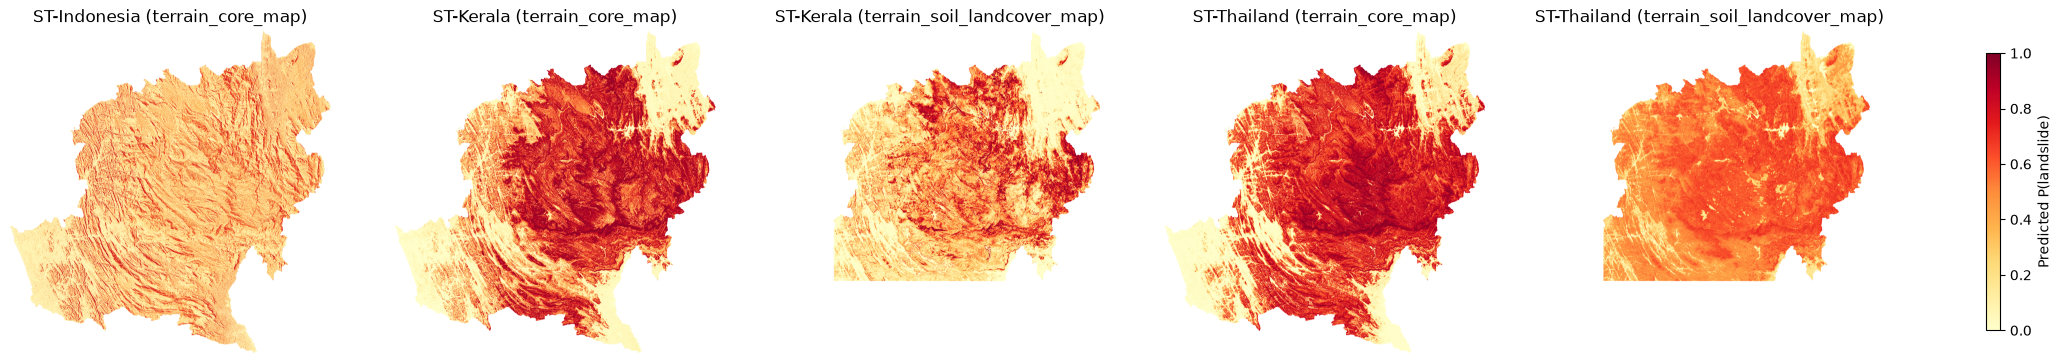

In [18]:
if scenario_maps:
    n = len(scenario_maps)
    fig, axes = plt.subplots(1, n, figsize=(6 * n, 6))
    if n == 1:
        axes = [axes]

    im = None
    for ax, (name, proba_map) in zip(axes, scenario_maps.items()):
        im = ax.imshow(proba_map, cmap="YlOrRd", vmin=0, vmax=1)
        ax.set_title(name)
        ax.axis("off")

    fig.colorbar(im, ax=axes, shrink=0.6, label="Predicted P(landslide)")
    fig.savefig(FIGURE_DIR / "susceptibility_maps_comparison.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("No scenario maps to plot -- run Sections 8a-8c first.")

## 9. Covariate-shift diagnostic: why does zero-shot transfer perform near-chance?

The results in Section 4 show ROC-AUC of only ~0.51-0.62 across every source/tier -- barely
better than random, with MCC near zero. Before concluding "transfer doesn't work," it's worth
checking *why*: if the source domain's feature distributions look very different from Sri
Lanka's, the source-trained decision boundary is being applied well outside the region of
feature space it was fit on, which is exactly the failure mode a Kolmogorov-Smirnov (KS) test on
each covariate will surface.

For each source domain, this compares the distribution of every transfer feature in the source
training data against the same feature in the Sri Lanka test set. A large KS statistic (rule of
thumb: > 0.2, or a significant p-value) flags a feature whose typical range/shape differs enough
between domains that a model trained on one is unlikely to generalise to the other.

In [19]:
from scipy.stats import ks_2samp

shift_rows = []
for source_name, cfg in SOURCE_CONFIG.items():
    if not cfg["csv"].exists():
        continue
    source_df = pd.read_csv(cfg["csv"])

    # Use the union of continuous features across this source's tiers so every feature it's
    # ever used for transfer gets checked, even if a given tier doesn't use all of them.
    all_continuous = sorted({c for tier in cfg["tiers"].values() for c in tier["continuous"]})

    for feature in all_continuous:
        if feature not in source_df.columns or feature not in sl_X_test_raw.columns:
            continue
        src_vals = source_df[feature].dropna()
        tgt_vals = sl_X_test_raw[feature].dropna()
        if len(src_vals) < 5 or len(tgt_vals) < 5:
            continue

        stat, pval = ks_2samp(src_vals, tgt_vals)
        shift_rows.append({
            "source": source_name,
            "feature": feature,
            "ks_statistic": round(stat, 4),
            "p_value": pval,
            "source_mean": round(src_vals.mean(), 3),
            "target_mean": round(tgt_vals.mean(), 3),
            "substantial_shift": stat > 0.2,
        })

shift_df = pd.DataFrame(shift_rows).sort_values(["source", "ks_statistic"], ascending=[True, False])
shift_df.to_csv(MODEL_DIR / "cross_domain_covariate_shift.csv", index=False)
shift_df

,source,feature,ks_statistic,p_value,source_mean,target_mean,substantial_shift
6,Indonesia,twi,0.7674,4.182026e-146,5.862,3.095,True
1,Indonesia,elev,0.4438,3.726918e-44,422.173,876.527,True
5,Indonesia,spi,0.3183,1.745415e-22,0.504,49.140,True
3,Indonesia,profc,0.2422,4.167453e-13,-0.001,-0.000,True
2,Indonesia,planc,0.1803,1.942965e-07,-0.001,-0.000,False
4,Indonesia,slope,0.1341,2.637778e-04,18.905,17.086,False
0,Indonesia,aspect,0.0419,7.649062e-01,171.564,174.777,False
17,Kerala,twi,0.7951,3.702779e-191,6.631,3.095,True
16,Kerala,spi,0.6432,1.475673e-114,644.436,49.140,True
9,Kerala,clay,0.5190,1.487598e-71,30.502,33.822,True


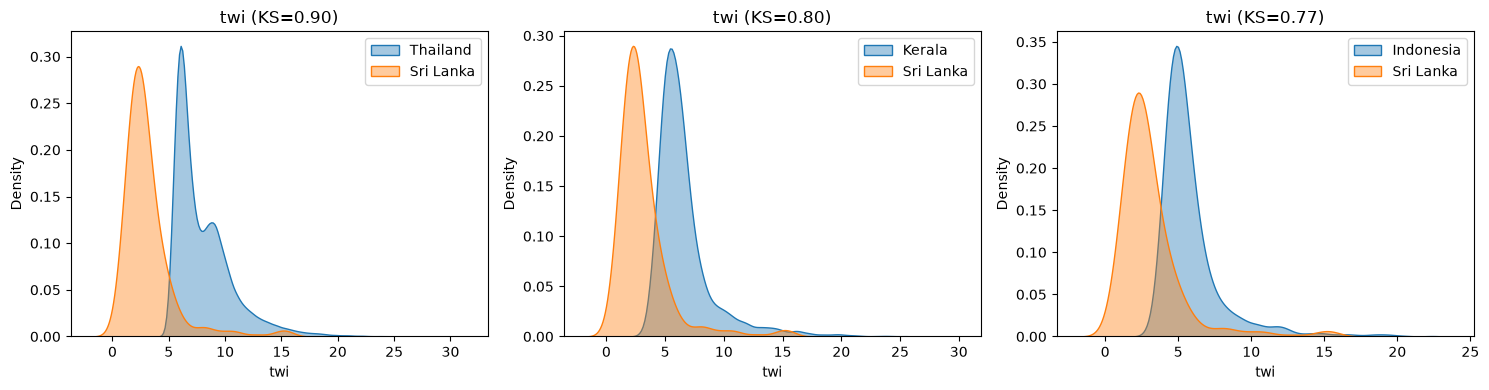

In [20]:
# Visualise the most-shifted feature per source as a quick sanity check
top_shifted = shift_df.sort_values("ks_statistic", ascending=False).groupby("source").head(1)

fig, axes = plt.subplots(1, len(top_shifted), figsize=(5 * len(top_shifted), 4))
if len(top_shifted) == 1:
    axes = [axes]

for ax, (_, row) in zip(axes, top_shifted.iterrows()):
    source_name, feature = row["source"], row["feature"]
    source_df = pd.read_csv(SOURCE_CONFIG[source_name]["csv"])
    sns.kdeplot(source_df[feature].dropna(), ax=ax, label=source_name, fill=True, alpha=0.4)
    sns.kdeplot(sl_X_test_raw[feature].dropna(), ax=ax, label="Sri Lanka", fill=True, alpha=0.4)
    ax.set_title(f"{feature} (KS={row['ks_statistic']:.2f})")
    ax.legend()

plt.tight_layout()
fig.savefig(FIGURE_DIR / "covariate_shift_top_features.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Threshold tuning (Youden's J) on a target-domain calibration split

Several scenarios above show the classic "miscalibrated cutoff" signature: recall as high as
0.90 with precision near 0.51 and TSS close to zero -- the model is defaulting to a 0.5
probability cutoff that doesn't match Sri Lanka's actual landslide prevalence.

This picks a better cutoff *without touching the held-out test set*: it uses a separate slice of
Sri Lanka's **training** data (never seen by the transfer models, and never used for the B-vs-ST
comparison) to find the threshold that maximises Youden's J = sensitivity + specificity - 1, then
applies that fixed threshold to the untouched test set.

**Adjust `SL_TRAIN_X_PATH` / `SL_TRAIN_Y_PATH` below** to whatever `08c_Sri_Lanka_modeling.ipynb`
actually named the Sri Lanka *training* split (parallel to `sri_lanka_X_test_raw.csv` /
`sri_lanka_y_test.csv` used in Section 1). If those files aren't available, this section will
print a warning and skip rather than guess.

In [21]:
SL_TRAIN_X_PATH = PROCESSED_DIR / "sri_lanka_X_train_raw.csv"
SL_TRAIN_Y_PATH = PROCESSED_DIR / "sri_lanka_y_train.csv"

SL_TRAIN_AVAILABLE = SL_TRAIN_X_PATH.exists() and SL_TRAIN_Y_PATH.exists()
if SL_TRAIN_AVAILABLE:
    sl_X_train_raw = pd.read_csv(SL_TRAIN_X_PATH)
    sl_y_train = pd.read_csv(SL_TRAIN_Y_PATH).squeeze("columns")
    print("Sri Lanka training split:", sl_X_train_raw.shape)
else:
    print(
        "Sri Lanka training split not found at the configured paths -- "
        "update SL_TRAIN_X_PATH / SL_TRAIN_Y_PATH above to run Sections 10-11."
    )

Sri Lanka training split: (1169, 20)


In [22]:
def find_best_threshold(y_true, y_proba):
    """Return the probability threshold that maximises Youden's J (sensitivity + specificity - 1)."""
    thresholds = np.linspace(0.01, 0.99, 99)
    best_t, best_j = 0.5, -np.inf
    for t in thresholds:
        y_pred = (y_proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
        sens = tp / (tp + fn) if (tp + fn) else 0.0
        spec = tn / (tn + fp) if (tn + fp) else 0.0
        j = sens + spec - 1
        if j > best_j:
            best_j, best_t = j, t
    return best_t, best_j


def evaluate_with_threshold(model, X, y, threshold):
    """Same metric suite as evaluate_binary_classifier, but with a custom decision threshold."""
    y_proba = model.predict_proba(X)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    sensitivity = tp / (tp + fn) if (tp + fn) else np.nan
    return {
        "accuracy": accuracy_score(y, y_pred),
        "precision": precision_score(y, y_pred, zero_division=0),
        "recall": recall_score(y, y_pred, zero_division=0),
        "specificity": specificity,
        "f1": f1_score(y, y_pred, zero_division=0),
        "mcc": matthews_corrcoef(y, y_pred),
        "tss": sensitivity + specificity - 1,
        "roc_auc": roc_auc_score(y, y_proba),          # unaffected by threshold
        "pr_auc": average_precision_score(y, y_proba),  # unaffected by threshold
        "brier": brier_score_loss(y, y_proba),           # unaffected by threshold
        "threshold_used": threshold,
    }

In [23]:
threshold_tuned_results = []

if SL_TRAIN_AVAILABLE:
    for key, pipeline in fitted_pipelines.items():
        source_name = key.split(" (")[0]
        tier_name, algorithm_name = key.split("(")[1].rstrip(")").split(", ")

        cols = SOURCE_CONFIG[source_name]["tiers"][tier_name]
        feature_cols = cols["continuous"] + cols["categorical"]

        train_valid = sl_X_train_raw[feature_cols].notna().all(axis=1)
        X_cal = sl_X_train_raw.loc[train_valid, feature_cols]
        y_cal = sl_y_train.loc[train_valid]
        if X_cal.empty:
            continue

        cal_proba = pipeline.predict_proba(X_cal)[:, 1]
        best_t, best_j = find_best_threshold(y_cal, cal_proba)

        test_valid = sl_X_test_raw[feature_cols].notna().all(axis=1)
        X_test = sl_X_test_raw.loc[test_valid, feature_cols]
        y_test = sl_y_test.loc[test_valid]

        result = evaluate_with_threshold(pipeline, X_test, y_test, best_t)
        result.update({
            "scenario": f"ST-{source_name} (thresh-tuned)",
            "feature_tier": tier_name,
            "algorithm": algorithm_name,
            "n_features": len(feature_cols),
            "n_target_eval_rows": int(test_valid.sum()),
            "calibration_youden_j": round(best_j, 4),
        })
        threshold_tuned_results.append(result)
        f1_val, auc_val = result['f1'], result['roc_auc']
        print(f"{key}: best threshold={best_t:.2f} (J={best_j:.3f}) -> F1={f1_val:.4f}, ROC-AUC={auc_val:.4f}")

threshold_tuned_df = pd.DataFrame(threshold_tuned_results)
threshold_tuned_df[display_cols + ["threshold_used"]].round(4) if not threshold_tuned_df.empty else threshold_tuned_df

Indonesia (terrain_core, Random Forest): best threshold=0.42 (J=0.202) -> F1=0.6575, ROC-AUC=0.6228
Indonesia (terrain_core, XGBoost): best threshold=0.24 (J=0.153) -> F1=0.6233, ROC-AUC=0.5874
Kerala (terrain_core, Random Forest): best threshold=0.51 (J=0.221) -> F1=0.5697, ROC-AUC=0.5416
Kerala (terrain_core, XGBoost): best threshold=0.76 (J=0.228) -> F1=0.5536, ROC-AUC=0.6038
Kerala (terrain_soil_landcover, Random Forest): best threshold=0.43 (J=0.209) -> F1=0.6168, ROC-AUC=0.5798
Kerala (terrain_soil_landcover, XGBoost): best threshold=0.11 (J=0.147) -> F1=0.6600, ROC-AUC=0.5792
Thailand (terrain_core, Random Forest): best threshold=0.49 (J=0.127) -> F1=0.6290, ROC-AUC=0.5160
Thailand (terrain_core, XGBoost): best threshold=0.73 (J=0.174) -> F1=0.5395, ROC-AUC=0.5617
Thailand (terrain_soil_landcover, Random Forest): best threshold=0.57 (J=0.197) -> F1=0.6032, ROC-AUC=0.6144
Thailand (terrain_soil_landcover, XGBoost): best threshold=0.80 (J=0.209) -> F1=0.5988, ROC-AUC=0.6030


,scenario,feature_tier,algorithm,n_features,n_target_eval_rows,accuracy,precision,recall,f1,roc_auc,mcc,tss,threshold_used
0,ST-Indonesia (thresh-tuned),terrain_core,Random Forest,7,293,0.5768,0.5509,0.8151,0.6575,0.6228,0.1763,0.1552,0.42
1,ST-Indonesia (thresh-tuned),terrain_core,XGBoost,7,293,0.5256,0.5157,0.7877,0.6233,0.5874,0.0621,0.0530,0.24
2,ST-Kerala (thresh-tuned),terrain_core,Random Forest,7,293,0.5256,0.5198,0.6301,0.5697,0.5416,0.0531,0.0519,0.51
3,ST-Kerala (thresh-tuned),terrain_core,XGBoost,7,293,0.5597,0.5594,0.5479,0.5536,0.6038,0.1194,0.1194,0.76
4,ST-Kerala (thresh-tuned),terrain_soil_landcover,Random Forest,12,293,0.5631,0.5479,0.7055,0.6168,0.5798,0.1327,0.1272,0.43
5,ST-Kerala (thresh-tuned),terrain_soil_landcover,XGBoost,12,293,0.5324,0.5175,0.9110,0.6600,0.5792,0.1027,0.0674,0.11
6,ST-Thailand (thresh-tuned),terrain_core,Random Forest,7,293,0.5290,0.5177,0.8014,0.6290,0.5160,0.0713,0.0599,0.49
7,ST-Thailand (thresh-tuned),terrain_core,XGBoost,7,293,0.5222,0.5190,0.5616,0.5395,0.5617,0.0448,0.0446,0.73
8,ST-Thailand (thresh-tuned),terrain_soil_landcover,Random Forest,12,293,0.5734,0.5621,0.6507,0.6032,0.6144,0.1491,0.1473,0.57
9,ST-Thailand (thresh-tuned),terrain_soil_landcover,XGBoost,12,293,0.5563,0.5449,0.6644,0.5988,0.6030,0.1161,0.1134,0.80


## 11. Fine-tuned transfer: source data + a small slice of Sri Lanka training data

Section 9 checks *whether* the domains differ; this checks how much Sri Lanka-specific data it
takes to close the gap. Tree ensembles don't support incremental fine-tuning the way neural nets
do, so the standard approach is **combined training**: retrain from scratch on the source
domain's data plus a small fraction of Sri Lanka's training rows, optionally upweighting the
target rows so a small sample isn't drowned out by a much larger source dataset.

This still evaluates on the same untouched Sri Lanka test set used everywhere else, so it's a
fair comparison against the zero-shot (Section 4) and threshold-tuned (Section 10) results.
`TARGET_FRACTION` controls how much Sri Lanka training data is "allowed" -- start small (0.1-0.2)
since the whole point is measuring how little target data is needed.

In [24]:
TARGET_FRACTION = 0.2          # fraction of Sri Lanka TRAINING rows to add in
TARGET_SAMPLE_WEIGHT = 5.0     # upweight target rows so a small sample isn't ignored

fine_tune_results = []
fine_tuned_pipelines = {}

if SL_TRAIN_AVAILABLE:
    rng = np.random.RandomState(RANDOM_STATE)

    for source_name, cfg in SOURCE_CONFIG.items():
        if not cfg["csv"].exists():
            continue
        source_df = pd.read_csv(cfg["csv"])

        for tier_name, cols in cfg["tiers"].items():
            feature_cols = cols["continuous"] + cols["categorical"]
            if any(c not in sl_X_train_raw.columns for c in feature_cols):
                continue

            # small, fixed-seed sample of Sri Lanka TRAINING rows (never the test set)
            train_valid = sl_X_train_raw[feature_cols].notna().all(axis=1)
            target_pool = sl_X_train_raw.loc[train_valid].copy()
            target_labels_pool = sl_y_train.loc[train_valid]
            n_target = max(1, int(len(target_pool) * TARGET_FRACTION))
            idx = rng.choice(target_pool.index, size=n_target, replace=False)
            X_target = target_pool.loc[idx, feature_cols]
            y_target = target_labels_pool.loc[idx]

            src_valid = source_df[feature_cols + ["label"]].dropna()
            X_source = src_valid[feature_cols]
            y_source = src_valid["label"].astype(int)

            X_combined = pd.concat([X_source, X_target], ignore_index=True)
            y_combined = pd.concat([y_source, y_target], ignore_index=True)
            sample_weight = np.concatenate([
                np.ones(len(X_source)),
                np.full(len(X_target), TARGET_SAMPLE_WEIGHT),
            ])

            for algorithm_name in ["Random Forest", "XGBoost"]:
                preprocessor = build_preprocessor(cols["continuous"], cols["categorical"])
                model = make_estimator(algorithm_name)
                pipeline = Pipeline([("preprocess", preprocessor), ("model", model)])
                pipeline.fit(X_combined, y_combined, model__sample_weight=sample_weight)

                test_valid = sl_X_test_raw[feature_cols].notna().all(axis=1)
                X_test = sl_X_test_raw.loc[test_valid, feature_cols]
                y_test = sl_y_test.loc[test_valid]

                metrics = evaluate_binary_classifier(pipeline, X_test, y_test)
                metrics.update({
                    "scenario": f"ST+FT-{source_name}",
                    "feature_tier": tier_name,
                    "algorithm": algorithm_name,
                    "n_features": len(feature_cols),
                    "n_target_eval_rows": int(test_valid.sum()),
                    "n_target_finetune_rows": n_target,
                })
                fine_tune_results.append(metrics)

                key = f"{source_name} ({tier_name}, {algorithm_name}, FT)"
                fine_tuned_pipelines[key] = pipeline
                ft_fname = f"finetune_{source_name}_{tier_name}_{algorithm_name}".replace(" ", "_") + ".joblib"
                joblib.dump(pipeline, MODEL_DIR / ft_fname)

    print(f"Fine-tuned {len(fine_tune_results)} (source, tier, algorithm) combinations "
          f"using {TARGET_FRACTION:.0%} of Sri Lanka training data.")
else:
    print("Skipping Section 11 -- Sri Lanka training split not available (see Section 10 setup).")

fine_tune_df = pd.DataFrame(fine_tune_results)
fine_tune_df[display_cols].round(4) if not fine_tune_df.empty else fine_tune_df

Fine-tuned 10 (source, tier, algorithm) combinations using 20% of Sri Lanka training data.


,scenario,feature_tier,algorithm,n_features,n_target_eval_rows,accuracy,precision,recall,f1,roc_auc,mcc,tss
0,ST+FT-Indonesia,terrain_core,Random Forest,7,293,0.6109,0.5941,0.6918,0.6392,0.6338,0.2253,0.2224
1,ST+FT-Indonesia,terrain_core,XGBoost,7,293,0.5666,0.5562,0.6438,0.5968,0.6197,0.1352,0.1336
2,ST+FT-Kerala,terrain_core,Random Forest,7,293,0.6007,0.5829,0.6986,0.6355,0.6365,0.2060,0.2020
3,ST+FT-Kerala,terrain_core,XGBoost,7,293,0.5802,0.5642,0.6918,0.6215,0.6247,0.1653,0.1612
4,ST+FT-Kerala,terrain_soil_landcover,Random Forest,12,293,0.5734,0.5614,0.6575,0.6057,0.6616,0.1494,0.1473
5,ST+FT-Kerala,terrain_soil_landcover,XGBoost,12,293,0.5495,0.5407,0.6370,0.5849,0.6359,0.1011,0.0996
6,ST+FT-Thailand,terrain_core,Random Forest,7,293,0.5836,0.5870,0.5548,0.5704,0.6512,0.1673,0.1670
7,ST+FT-Thailand,terrain_core,XGBoost,7,293,0.5836,0.5800,0.5959,0.5878,0.6334,0.1674,0.1673
8,ST+FT-Thailand,terrain_soil_landcover,Random Forest,12,293,0.6007,0.5901,0.6507,0.6189,0.6523,0.2027,0.2017
9,ST+FT-Thailand,terrain_soil_landcover,XGBoost,12,293,0.5870,0.5749,0.6575,0.6134,0.6621,0.1763,0.1745


## 12. Consolidated comparison: zero-shot vs. threshold-tuned vs. fine-tuned

In [25]:
zero_shot_df = transfer_results_df.copy()
zero_shot_df["scenario"] = zero_shot_df["scenario"]  # already "ST-{source}"

frames = [zero_shot_df]
if not threshold_tuned_df.empty:
    frames.append(threshold_tuned_df)
if not fine_tune_df.empty:
    frames.append(fine_tune_df)

full_comparison_df = pd.concat(frames, ignore_index=True, sort=False)
full_comparison_df.to_csv(MODEL_DIR / "cross_domain_transfer_full_comparison.csv", index=False)
full_comparison_df.to_json(
    MODEL_DIR / "cross_domain_transfer_full_comparison.json", orient="records", indent=2
)

cols_to_show = [c for c in display_cols if c in full_comparison_df.columns]
full_comparison_df[cols_to_show].sort_values(["feature_tier", "scenario"]).round(4)

,scenario,feature_tier,algorithm,n_features,n_target_eval_rows,accuracy,precision,recall,f1,roc_auc,mcc,tss
20,ST+FT-Indonesia,terrain_core,Random Forest,7,293,0.6109,0.5941,0.6918,0.6392,0.6338,0.2253,0.2224
21,ST+FT-Indonesia,terrain_core,XGBoost,7,293,0.5666,0.5562,0.6438,0.5968,0.6197,0.1352,0.1336
22,ST+FT-Kerala,terrain_core,Random Forest,7,293,0.6007,0.5829,0.6986,0.6355,0.6365,0.2060,0.2020
23,ST+FT-Kerala,terrain_core,XGBoost,7,293,0.5802,0.5642,0.6918,0.6215,0.6247,0.1653,0.1612
26,ST+FT-Thailand,terrain_core,Random Forest,7,293,0.5836,0.5870,0.5548,0.5704,0.6512,0.1673,0.1670
27,ST+FT-Thailand,terrain_core,XGBoost,7,293,0.5836,0.5800,0.5959,0.5878,0.6334,0.1674,0.1673
0,ST-Indonesia,terrain_core,Random Forest,7,293,0.5939,0.6031,0.5411,0.5704,0.6228,0.1884,0.1874
1,ST-Indonesia,terrain_core,XGBoost,7,293,0.5631,0.5714,0.4932,0.5294,0.5874,0.1271,0.1258
10,ST-Indonesia (thresh-tuned),terrain_core,Random Forest,7,293,0.5768,0.5509,0.8151,0.6575,0.6228,0.1763,0.1552
11,ST-Indonesia (thresh-tuned),terrain_core,XGBoost,7,293,0.5256,0.5157,0.7877,0.6233,0.5874,0.0621,0.0530


metric_to_plot = "f1"
plot_df = full_comparison_df.copy()
plot_df["source"] = plot_df["scenario"].str.extract(r"ST\+?FT?-?(\w+)")
plot_df["stage"] = np.select(
    [plot_df["scenario"].str.contains("thresh-tuned"), plot_df["scenario"].str.contains(r"^ST\+FT")],
    ["threshold-tuned", "fine-tuned"],
    default="zero-shot",
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=plot_df, x="source", y=metric_to_plot, hue="stage", ax=ax, errorbar=None)
ax.set_title(f"{metric_to_plot.upper()} by source domain and adaptation stage")
ax.set_ylabel(metric_to_plot.upper())
ax.set_xlabel("Source domain")
ax.legend(title="Stage")
fig.savefig(FIGURE_DIR / "transfer_stages_comparison.png", dpi=300, bbox_inches="tight")
plt.show()